# Laptop price prediction

How well do a laptop's specifications predict its listed price, and how much does a nonlinear model add over a linear one? This notebook explores the IBM laptop pricing dataset and runs the grouped, nested cross-validation in `analysis.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image

import analysis

data = analysis.load_data()
print(data.shape)
data.head()

(238, 12)


,Manufacturer,Category,Screen,GPU,OS,CPU_core,Screen_Size_inch,CPU_frequency,RAM_GB,Storage_GB_SSD,Weight_kg,Price
0,Acer,4,IPS Panel,2,1,5,35.560,1.6,8,256,1.60,978
1,Dell,3,Full HD,1,1,3,39.624,2.0,4,256,2.20,634
2,Dell,3,Full HD,1,1,7,39.624,2.7,8,256,2.20,946
3,Dell,4,IPS Panel,2,1,5,33.782,1.6,8,128,1.22,1244
4,HP,4,Full HD,2,1,7,39.624,1.8,8,256,1.91,837


## Price distribution and the strongest single drivers

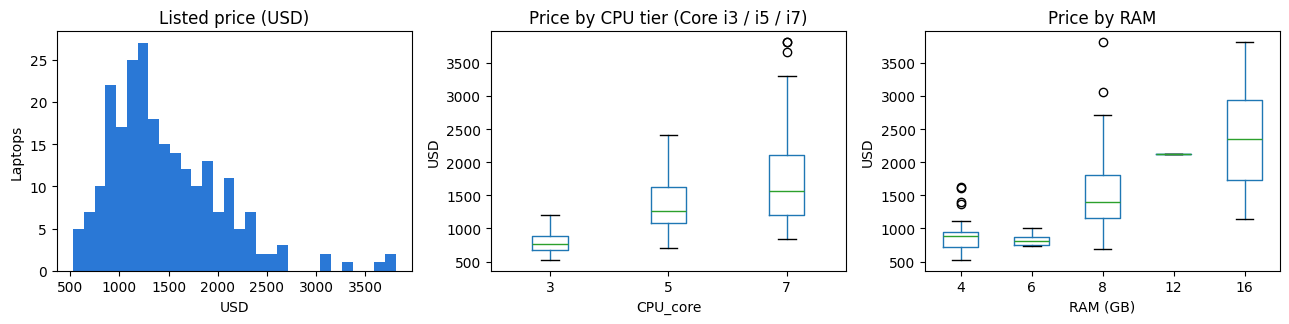

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(data['Price'], bins=30, color='#2a78d6')
axes[0].set(title='Listed price (USD)', xlabel='USD', ylabel='Laptops')
data.boxplot(column='Price', by='CPU_core', ax=axes[1], grid=False)
axes[1].set(title='Price by CPU tier (Core i3 / i5 / i7)', xlabel='CPU_core', ylabel='USD')
data.boxplot(column='Price', by='RAM_GB', ax=axes[2], grid=False)
axes[2].set(title='Price by RAM', xlabel='RAM (GB)', ylabel='USD')
fig.suptitle('')
fig.tight_layout()
plt.show()

## Duplicate specifications

Some laptops share every specification but list at different prices. They're kept together in one group so a configuration never appears in both a training and a validation fold.

In [3]:
groups = analysis.spec_groups(data)
print(f"{len(data)} rows, {groups.max() + 1} distinct specifications, "
      f"{pd.Series(groups).duplicated(keep=False).sum()} rows share a specification with another row")

238 rows, 226 distinct specifications, 24 rows share a specification with another row


## Run the analysis

10 repeats of grouped 5-fold cross-validation, with hyperparameters tuned by an inner grouped 5-fold grid search. About one minute.

In [4]:
metrics = analysis.run()
cv = pd.read_csv('outputs/cv_comparison.csv')
cv.pivot(index='model', columns='metric', values='mean').round(3)

metric,mae_usd,r2,rmse_usd
model,,,
mean_baseline,445.219,-0.009,576.064
random_forest,249.735,0.631,348.302
ridge,291.866,0.499,405.906


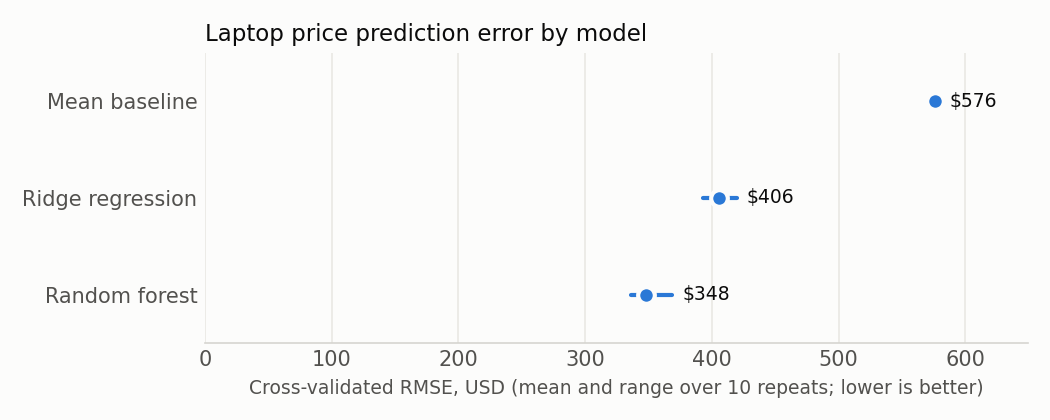

In [5]:
Image(filename='outputs/figures/cv_rmse.png', width=650)

## Prediction intervals

The best model family is refit on 60% of the rows, a split-conformal 90% interval is calibrated on another 20%, and coverage is checked once on the last 20%.

In [6]:
pd.Series({k: v for k, v in metrics['conformal_interval'].items() if k != 'test_metrics'})

model                                                      random_forest
split_rows                 {'train': 142, 'calibration': 48, 'test': 48}
nominal_coverage                                                     0.9
half_width_usd                                                    959.37
empirical_test_coverage                                         0.958333
dtype: object

## Largest ridge coefficients (numeric features standardized)

In [7]:
pd.read_csv('outputs/coefficients.csv').head(10)

,feature,coefficient_usd
0,cat__Manufacturer_Razer,568.200777
1,cat__Category_5,451.853066
2,cat__Category_3,-349.278248
3,cat__Category_1,-335.450852
4,cat__Manufacturer_Acer,-309.355584
5,cat__Category_2,263.344720
6,cat__Manufacturer_Toshiba,223.091008
7,cat__Manufacturer_Asus,-216.363637
8,cat__GPU_1,-204.005261
9,cat__Manufacturer_Xiaomi,-195.294826
